In [1]:
pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from PIL import Image
print("Libraries imported successfully")

Libraries imported successfully


In [3]:
print(os.path.expanduser("~/Documents"))

C:\Users\HP/Documents


In [4]:
print(os.listdir(os.path.expanduser("~/Documents")))

['anaconda_projects', 'desktop.ini', 'IntelImageClassification', 'KingsoftData', 'My Music', 'My Pictures', 'My Videos', 'tcs.txt', 'WindowsPowerShell']


In [5]:
TRAIN_DIR = os.path.expanduser("~/Documents/IntelImageClassification/seg_train/seg_train")
TEST_DIR = os.path.expanduser("~/Documents/IntelImageClassification/seg_test/seg_test")

In [6]:
print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))

Training folder exists: True
Testing folder exists: True


## Find the classes

In [7]:
classes = sorted(os.listdir(TRAIN_DIR))

print("Classes:")
print(classes)
# os.listdir(TRAIN_DIR) looks inside your training folder and gets the folder names.
# Each folder represents one image class.sorted() simply puts them in alphabetical order.

Classes:
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## Count images in each class

In [8]:
counts=[]
for c in classes:
    folders=os.path.join(TRAIN_DIR,c)
    numOfImages=len(os.listdir(folders))
    print(c,":",numOfImages)
    counts.append(numOfImages)

buildings : 2191
forest : 2271
glacier : 2404
mountain : 2512
sea : 2274
street : 2382


## Check if the dataset is balanced

In [9]:
print("Maximum images:", max(counts))
print("Minimum images:", min(counts))

Maximum images: 2512
Minimum images: 2191


In [10]:
difference = max(counts) - min(counts)
print("Difference:", difference)
ratio = max(counts) / min(counts)
print("Ratio:", ratio)

Difference: 321
Ratio: 1.1465084436330444


In [11]:
if ratio < 1.5:
    print("Balanced")
else:
    print("Imbalanced")

Balanced


##### another method

In [12]:
avg=sum(counts)/len(counts)
max_diff=(max(counts)-avg)/avg*100
min_diff=(avg-min(counts))/avg*100
print("avg:",avg)
print("max_diff:",max_diff)
print("min_diff:",min_diff)

avg: 2339.0
max_diff: 7.396323215049167
min_diff: 6.327490380504488


That is a small difference, so I would describe your dataset as reasonably balanced.The six classes contain a relatively similar number of images, ranging from 2,191 to 2,512 images. Therefore, there is no substantial class imbalance in the training dataset."

## Display 5 sample images

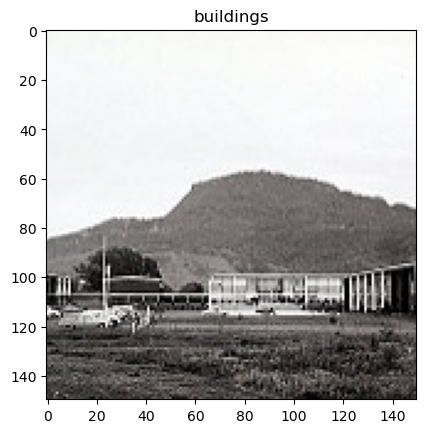

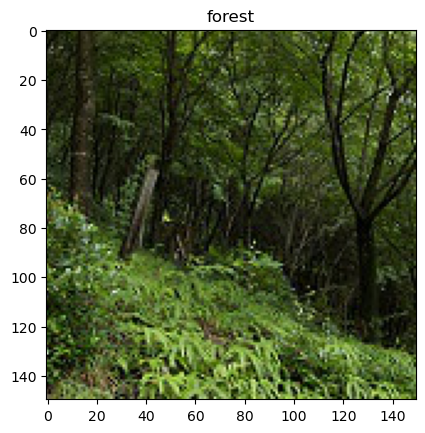

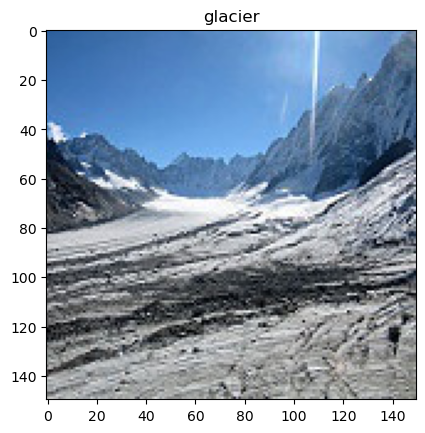

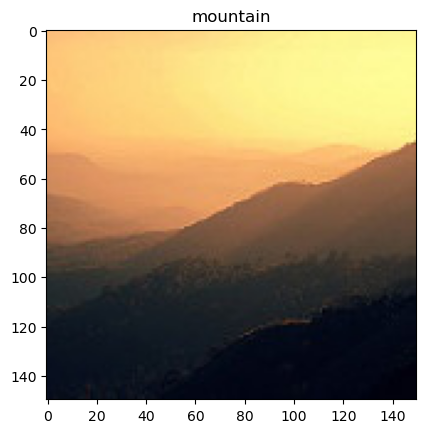

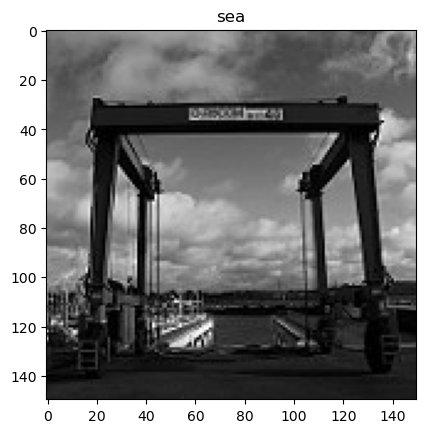

In [13]:
for c in classes[:5]:
    folder=os.path.join(TRAIN_DIR,c)
    image_path=os.listdir(folder)[0]
    img = Image.open(os.path.join(folder, image_path))
    plt.imshow(img)
    plt.title(c)
    plt.show()

# Image Preprocessing

In [14]:

!pip install tensorflow
import tensorflow as tf

In [15]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

In [16]:
train_ds=tf.keras.utils.image_dataset_from_directory(TRAIN_DIR,
                                                   validation_split=0.2,
                                                   subset="training",
                                                   seed=42,
                                                   image_size=IMG_SIZE,
                                                   batch_size=BATCH_SIZE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.


In [17]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 14034 files belonging to 6 classes.
Using 2806 files for validation.


In [18]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 3000 files belonging to 6 classes.


In [19]:
print(train_ds.class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [20]:
print(len(train_ds))
print(len(val_ds))
print(len(test_ds))

351
88
94


# Building the CNN

In [21]:
model=tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(32,(3,3),activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
 tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(6, activation="softmax")
])

In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",#suitable for our integer class labels.
    metrics=["accuracy"]
)

# Feature Extraction

#### Understand what the CNN extracts
#### See the CNN layers-model.summary()

## Now train the CNN

In [24]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 160s 445ms/step - accuracy: 0.6536 - loss: 0.9404 - val_accuracy: 0.7231 - val_loss: 0.7519
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 148s 421ms/step - accuracy: 0.8068 - loss: 0.5410 - val_accuracy: 0.7537 - val_loss: 0.7030
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 148s 422ms/step - accuracy: 0.8995 - loss: 0.2958 - val_accuracy: 0.7512 - val_loss: 0.8743
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 152s 433ms/step - accuracy: 0.9566 - loss: 0.1378 - val_accuracy: 0.7701 - val_loss: 0.9875
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 156s 445ms/step - accuracy: 0.9812 - loss: 0.0719 - val_accuracy: 0.7587 - val_loss: 1.0928
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 151s 430ms/step - accuracy: 0.9872 - loss: 0.0441 - val_accuracy: 0.7801 - val_loss: 1.1480
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 149s 425ms/step - accuracy: 0.9835 - loss: 0.0596 - val_accuracy: 0.7698 - val_loss: 1.1940
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 151s 430ms/step - accuracy: 0.9890 -

# Evaluate the model

In [25]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
# model.evaluate() tests your trained CNN using the test dataset.
# test_accuracy tells us how accurately the model predicts the six classes.
# test_loss tells us the model's prediction error.

94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.7593 - loss: 1.5366
Test Accuracy: 0.7593333125114441


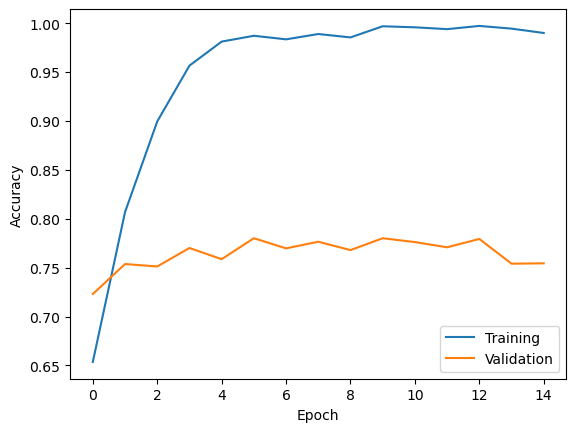

In [26]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training","Validation"])
plt.show()

Training accuracy → how well the model performs on training images.
Validation accuracy → how well it performs on unseen validation images
##### If both generally increase together → the model is learning.
##### If training accuracy becomes much higher than validation accuracy → this can indicate overfitting.

The training accuracy increases continuously and reaches nearly 100%, while validation accuracy remains around 75%. This large difference indicates that the CNN is overfitting the training data and has limited generalization to unseen images.

## plot loss

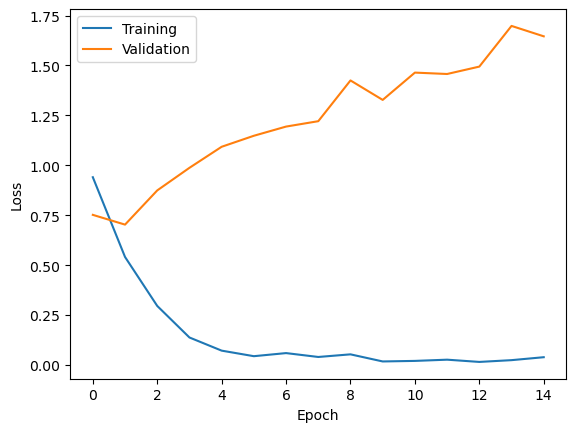

In [27]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])

plt.show()

Lower loss = better
These plots will help us complete the assignment's overfitting/underfitting analysis.

The CNN shows signs of overfitting. The training loss decreases continuously, while the validation loss starts increasing after the initial epochs. This indicates that the model is learning the training data very well but is not generalizing well to unseen validation data.

# Data Augmentation

In [28]:
data_augmentation=tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])
# RandomFlip      → flips the image horizontally
# RandomRotation  → slightly rotates the image
# RandomZoom      → slightly zooms the image

## Create the improved CNN

In [29]:
model2 = tf.keras.Sequential([
    data_augmentation,

    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    #0.5 means that during training, approximately 50% of the neurons in that layer are temporarily ignored. 
    #This helps prevent the model from relying too heavily on particular neurons and can reduce overfitting.

    tf.keras.layers.Dense(6, activation="softmax")
])

### Compile the new model

In [30]:
model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [31]:
model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Train model2

In [32]:
history2 = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 179s 503ms/step - accuracy: 0.5205 - loss: 1.2360 - val_accuracy: 0.6814 - val_loss: 0.8642
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 169s 482ms/step - accuracy: 0.6331 - loss: 0.9804 - val_accuracy: 0.7363 - val_loss: 0.7245
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 3519s 10s/step - accuracy: 0.6651 - loss: 0.9081 - val_accuracy: 0.7149 - val_loss: 0.7618
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 177s 504ms/step - accuracy: 0.6974 - loss: 0.8460 - val_accuracy: 0.7448 - val_loss: 0.6858
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 178s 507ms/step - accuracy: 0.7060 - loss: 0.8117 - val_accuracy: 0.7691 - val_loss: 0.6240
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 176s 502ms/step - accuracy: 0.7171 - loss: 0.7822 - val_accuracy: 0.7534 - val_loss: 0.6829
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 176s 502ms/step - accuracy: 0.7284 - loss: 0.7514 - val_accuracy: 0.7908 - val_loss: 0.5886
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 192s 547ms/step - accuracy: 0.7442 - 

Test model2

In [33]:
test_loss2, test_accuracy2 = model2.evaluate(test_ds)

print("Test Accuracy:", test_accuracy2)

94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.8003 - loss: 0.5694
Test Accuracy: 0.8003333210945129


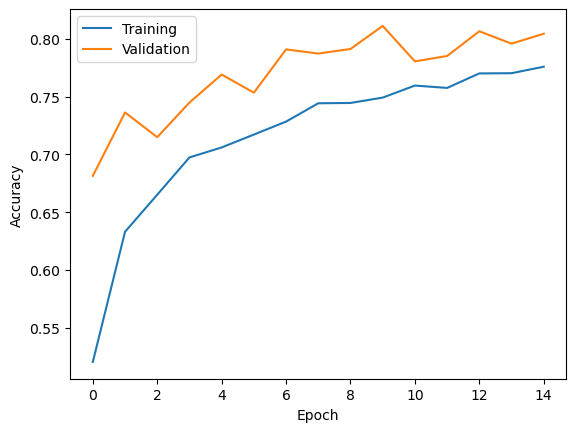

In [34]:
plt.plot(history2.history["accuracy"])
plt.plot(history2.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])

plt.show()

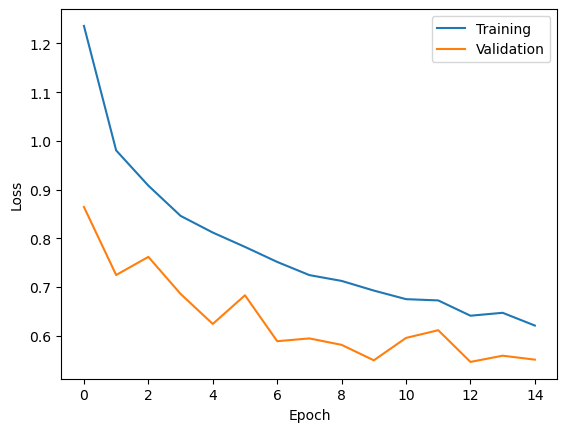

In [35]:
plt.plot(history2.history["loss"])
plt.plot(history2.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])

plt.show()

#### After applying data augmentation and dropout, the gap between training and validation performance became smaller. The validation loss remained relatively stable, and training and validation accuracy became closer. Therefore, the use of augmentation and dropout helped reduce overfitting and improved the model's generalization.

## Detailed Evaluation
### Get predictions from the test data

In [36]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model2.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions.argmax(axis=1))

    # y_true → contains the actual class of each test image.
# y_pred → contains the class predicted by our CNN.
# argmax(axis=1) → selects the class with the highest probability.

In [37]:
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Actual labels: 3000
Predicted labels: 3000


## Classification report

In [38]:
from sklearn.metrics import classification_report

In [39]:
print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.class_names
))

              precision    recall  f1-score   support

   buildings       0.73      0.82      0.77       437
      forest       0.93      0.97      0.95       474
     glacier       0.86      0.61      0.72       553
    mountain       0.71      0.80      0.75       525
         sea       0.79      0.82      0.80       510
      street       0.82      0.81      0.82       501

    accuracy                           0.80      3000
   macro avg       0.81      0.81      0.80      3000
weighted avg       0.81      0.80      0.80      3000



## Confusion matrix

In [40]:
from sklearn.metrics import confusion_matrix

In [41]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[359   5   2   9   6  56]
 [  6 458   0   5   0   5]
 [ 21   6 340 117  49  20]
 [ 14   5  34 420  51   1]
 [ 30   6  16  35 417   6]
 [ 64  15   3   5   7 407]]


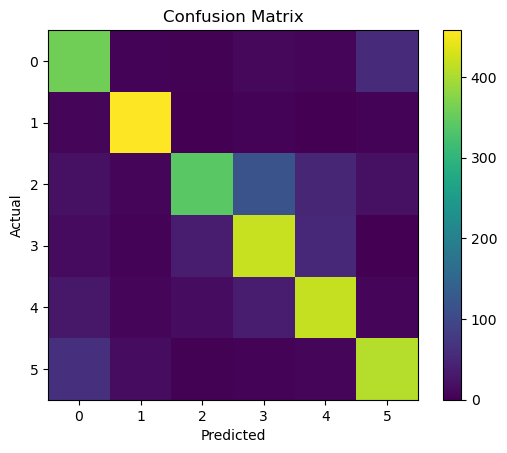

In [42]:
plt.imshow(cm)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.colorbar()
plt.show()

Your confusion matrix looks good in the sense that the largest values are mostly along the diagonal, which means many images are being classified correctly.

## Show 10 predictions

In [43]:
for images, labels in test_ds.take(1):
    predictions = model2.predict(images, verbose=0)

    for i in range(10):
        predicted_class = test_ds.class_names[predictions[i].argmax()]
        actual_class = test_ds.class_names[labels[i]]

        print("Actual:", actual_class, "| Predicted:", predicted_class)

Actual: buildings | Predicted: buildings
Actual: forest | Predicted: forest
Actual: mountain | Predicted: mountain
Actual: mountain | Predicted: mountain
Actual: mountain | Predicted: mountain
Actual: street | Predicted: street
Actual: forest | Predicted: forest
Actual: buildings | Predicted: buildings
Actual: glacier | Predicted: street
Actual: glacier | Predicted: mountain


## Transfer Learning

In [44]:
from tensorflow.keras.applications import MobileNetV2

Create the MobileNetV2 base model

In [45]:
#Create the MobileNetV2 base model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

C:\Users\HP\AppData\Local\Temp\ipykernel_10192\3820101312.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


MobileNetV2 is a pre-trained CNN model.
Instead of learning everything from the beginning, we use features that the model has already learned from a large image dataset.

weights="imagenet" → use the pre-trained weights.
include_top=False → remove the original classification layer.
input_shape=(150,150,3) → our images are 150 × 150 with 3 color channels (RGB).

In [46]:
base_model.trainable = False
# We keep the already-learned MobileNetV2 features unchanged while training our new classification layers.

In [47]:
transfer_model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(6, activation="softmax")
])

## Compile it

In [48]:
transfer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [49]:
transfer_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Train the model

In [50]:
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 184s 494ms/step - accuracy: 0.6909 - loss: 0.8006 - val_accuracy: 0.7530 - val_loss: 0.6473
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 183s 522ms/step - accuracy: 0.7626 - loss: 0.6164 - val_accuracy: 0.7605 - val_loss: 0.6320
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 179s 509ms/step - accuracy: 0.7891 - loss: 0.5539 - val_accuracy: 0.7491 - val_loss: 0.6633
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 175s 498ms/step - accuracy: 0.8042 - loss: 0.5215 - val_accuracy: 0.7676 - val_loss: 0.6214
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 178s 508ms/step - accuracy: 0.8107 - loss: 0.4867 - val_accuracy: 0.7594 - val_loss: 0.6532
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 172s 489ms/step - accuracy: 0.8227 - loss: 0.4606 - val_accuracy: 0.7787 - val_loss: 0.6106
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 171s 487ms/step - accuracy: 0.8362 - loss: 0.4352 - val_accuracy: 0.7783 - val_loss: 0.6111
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 170s 485ms/step - accuracy: 0.8506 -

train_ds → trains the new classification layers.
val_ds → checks performance on validation images.
epochs=15 → trains for 15 rounds.
The MobileNetV2 base is frozen, so its pre-trained features aren't changed.

## Evaluate MobileNetV2

In [51]:
transfer_loss, transfer_accuracy = transfer_model.evaluate(test_ds)
print("MobileNetV2 Test Accuracy:", transfer_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 37s 392ms/step - accuracy: 0.7520 - loss: 0.7450
MobileNetV2 Test Accuracy: 0.7519999742507935


## Compare both models

In [52]:
print("CNN Accuracy:", test_accuracy2)
print("MobileNetV2 Accuracy:", transfer_accuracy)

CNN Accuracy: 0.8003333210945129
MobileNetV2 Accuracy: 0.7519999742507935


One important note: your MobileNetV2 model was trained using train_ds, which already contains pixel values normalized by the CNN's Rescaling(1./255) layer. MobileNetV2 normally expects its own preprocessing, so we should account for that when preparing the final app to ensure its predictions are consistent with training.

## Final step: Streamlit deployment

In [68]:
model2.save("intel_cnn_model.keras")
# Save your trained model

In [75]:

%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="VisionAI | Image Classifier",
    page_icon="🌄",
    layout="wide"
)

# Custom interface styling
st.markdown("""
<style>
.stApp {
    background: linear-gradient(135deg, #10172a, #24205b, #173e65);
    color: white;
}

.block-container {
    padding-top: 2rem;
    max-width: 1150px;
}

.hero {
    text-align: center;
    padding: 35px 15px;
    border-radius: 24px;
    background: linear-gradient(120deg, #6c45e8, #147dba, #16b8a6);
    margin-bottom: 28px;
    box-shadow: 0 12px 35px #00000035;
}

.hero h1 {
    color: white;
    font-size: 43px;
    margin-bottom: 8px;
}

.hero p {
    color: #f0faff;
    font-size: 17px;
}

.info-card {
    background: #ffffff12;
    border: 1px solid #ffffff30;
    border-radius: 18px;
    padding: 22px;
    text-align: center;
    margin-bottom: 20px;
}

.result-card {
    background: linear-gradient(135deg, #184e77, #246b79);
    border: 1px solid #65e6d5;
    border-radius: 20px;
    padding: 25px;
    margin-top: 20px;
}

div[data-testid="stFileUploader"] {
    background: #ffffff0d;
    border: 1px dashed #8b9cff;
    border-radius: 18px;
    padding: 18px;
}

.stButton button {
    background: linear-gradient(90deg, #8b5cf6, #06b6d4);
    color: white;
    border: none;
    border-radius: 12px;
    padding: 10px 24px;
    font-weight: bold;
}

footer {
    visibility: hidden;
}

/* Make the upload text and Browse button visible */
div[data-testid="stFileUploader"] label {
    color: white !important;
}

div[data-testid="stFileUploader"] section {
    background-color: #f8fafc !important;
    border-radius: 14px !important;
}

div[data-testid="stFileUploader"] section button {
    background: linear-gradient(90deg, #7c3aed, #0891b2) !important;
    color: white !important;
    border: none !important;
    border-radius: 8px !important;
}

div[data-testid="stFileUploader"] section button:hover {
    background: #6d28d9 !important;
    color: white !important;
}

div[data-testid="stFileUploader"] small {
    color: #334155 !important;
}

</style>
""", unsafe_allow_html=True)

# Load the trained CNN model
@st.cache_resource
def load_model():
    return tf.keras.models.load_model("intel_cnn_model.keras")

model = load_model()

classes = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

class_emojis = {
    "buildings": "🏙️",
    "forest": "🌲",
    "glacier": "🧊",
    "mountain": "⛰️",
    "sea": "🌊",
    "street": "🛣️"
}

# Header
st.markdown("""
<div class="hero">
    <h1>🌎 VisionAI</h1>
    <p>Explore the power of Computer Vision</p>
    <p>Upload a landscape image and let AI discover its category.</p>
</div>
""", unsafe_allow_html=True)

# Information cards
col1, col2, col3 = st.columns(3)

with col1:
    st.markdown("""
    <div class="info-card">
        <h2>🧠 CNN</h2>
        <p>Deep Learning Model</p>
    </div>
    """, unsafe_allow_html=True)

with col2:
    st.markdown("""
    <div class="info-card">
        <h2>📸 6 Classes</h2>
        <p>Six scene categories</p>
    </div>
    """, unsafe_allow_html=True)

with col3:
    st.markdown("""
    <div class="info-card">
        <h2>⚡ Real-time</h2>
        <p>Instant predictions</p>
    </div>
    """, unsafe_allow_html=True)

st.markdown("## 📤 Upload Your Image")
st.write("Choose a JPG, JPEG, or PNG image to get started.")

uploaded_file = st.file_uploader(
    "Choose an image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    image_col, result_col = st.columns([1, 1], gap="large")

    with image_col:
        st.markdown("### 🖼️ Your Image")
        st.image(image, use_container_width=True)

    with result_col:
        st.markdown("### ✨ AI Prediction")

        resized_image = image.resize((150, 150))
        image_array = np.array(resized_image)
        image_array = np.expand_dims(image_array, axis=0)

        predictions = model.predict(image_array, verbose=0)[0]

        predicted_index = int(np.argmax(predictions))
        predicted_class = classes[predicted_index]
        confidence = float(predictions[predicted_index])

        st.markdown(
            f"""
            <div class="result-card">
                <h2>{class_emojis[predicted_class]} {predicted_class.title()}</h2>
                <p>Predicted scene category</p>
                <h1>{confidence * 100:.2f}%</h1>
                <p>Prediction confidence</p>
            </div>
            """,
            unsafe_allow_html=True
        )

        st.write("Confidence level")
        st.progress(confidence)

    st.markdown("## 📊 Class-wise Prediction Scores")

    for i, class_name in enumerate(classes):
        score = float(predictions[i])
        st.write(f"{class_emojis[class_name]} {class_name.title()} — {score * 100:.2f}%")
        st.progress(score)

else:
    st.markdown("""
    <div class="info-card">
        <h2>🌈 Ready to Explore?</h2>
        <p>Upload an image to see your AI model in action.</p>
        <p>Buildings · Forest · Glacier · Mountain · Sea · Street</p>
    </div>
    """, unsafe_allow_html=True)

st.markdown("---")
st.markdown(
    "<p style='text-align:center;color:#b9c5ed;'>"
    "VisionAI | Intel Image Classification Project | Built with TensorFlow & Streamlit"
    "</p>",
    unsafe_allow_html=True
)


Overwriting app.py


In [76]:
import os

print(os.getcwd())
print(os.path.exists("app.py"))
print(os.path.exists("intel_cnn_model.keras"))

C:\Users\HP\anaconda_projects\db
True
True


In [71]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [72]:
!streamlit run app.py

^C


In [77]:
import os
print(os.getcwd())

C:\Users\HP\anaconda_projects\db


In [80]:
!pip freeze > requirements12.txt